In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import math

from sklearn.linear_model import LinearRegression, QuantileRegressor, LogisticRegression, LogisticRegressionCV
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.metrics import r2_score

sns.set_theme(style="darkgrid")

# Univariate regression

Oefening 1.1: Lees met pd.read_csv het bestand ../data/uber_2025.csv in. Deze bevat 2000 (willekeurig gekozen) uber ritten in New York in Januari 2025. Maak een scatterplot van 'base_passenger_fare' t.o.v. 'trip_miles'.

In [2]:
uber_df_2025 = pd.read_csv('../../data/uber_2025.csv') # Adjust path to file location

In [3]:
uber_df_2025.sample(5)

,app_used,ride_id,request_datetime,on_scene_datetime,pickup_datetime,dropoff_datetime,pickup_zone_id,dropoff_zone_id,trip_miles,trip_seconds,base_passenger_fare,tolls,sales_tax,tips,driver_pay
1793,Uber,1410168,2025-01-03 12:19:07,2025-01-03 12:20:17,2025-01-03 12:22:18,2025-01-03 13:14:24,238,225,11.40,3126,47.81,0.0,4.23,0.0,45.88
114,Uber,4584528,2025-01-08 14:57:16,2025-01-08 15:03:27,2025-01-08 15:03:27,2025-01-08 15:12:00,85,89,0.77,513,8.93,0.0,0.79,1.0,7.57
1007,Uber,9800477,2025-01-16 13:35:11,2025-01-16 13:36:56,2025-01-16 13:38:56,2025-01-16 13:52:21,97,231,2.91,805,20.22,0.0,1.91,0.0,11.79
366,Uber,17277610,2025-01-27 08:33:28,2025-01-27 08:35:48,2025-01-27 08:37:00,2025-01-27 08:45:52,77,177,1.26,532,11.95,0.0,1.13,0.0,6.88
1636,Uber,17499186,2025-01-27 15:47:45,2025-01-27 15:50:35,2025-01-27 15:50:38,2025-01-27 16:35:35,258,112,8.22,2697,29.22,0.0,2.55,0.0,37.39


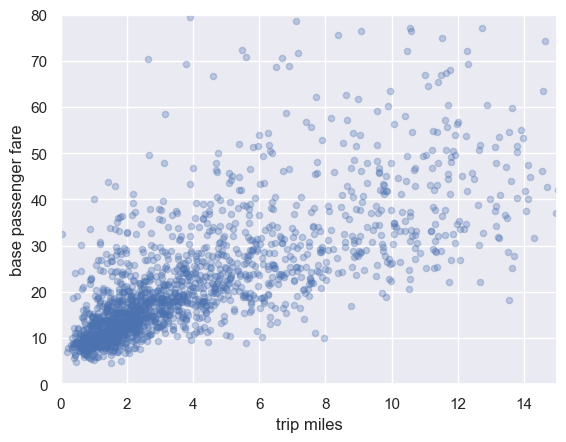

In [4]:
fig, ax = plt.subplots()

ax.scatter(
        uber_df_2025['trip_miles'], 
        uber_df_2025['base_passenger_fare'], 
        alpha=0.3,           
        s=20         
    )


ax.set_xlim(0, 15)
ax.set_ylim(0,80)


ax.set_xlabel('trip miles', fontsize=12)
ax.set_ylabel('base passenger fare', fontsize=12)

plt.show()

Oefening 1.2: Train met sklearn.LinearRegression een model dat de base_passenger_fare uit de trip_miles voorspelt.
Plot deze voorspelling bovenop de scatterplot uit 1.1. 
Gebruik sklearn.metrics.r2_score(df['base_passenger_fare'], df['jouw_voorspelling']) om in te schatten hoe goed je voorspelling is. 

Hint: Zorg bij het maken van een lijnplot er voor dat de datapunten in de juiste volgorde staan...

a=[[3.05838518]], b=[9.60056976]
r2 score: 0.6921048040435018


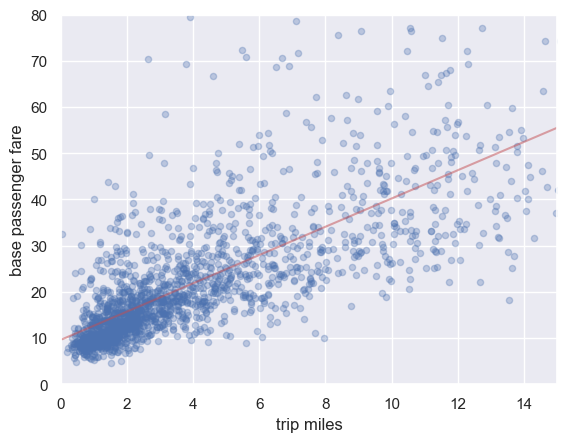

In [5]:
lr_model = LinearRegression()
lr_model.fit(uber_df_2025[['trip_miles']], uber_df_2025[['base_passenger_fare']])

print(f"a={lr_model.coef_}, b={lr_model.intercept_}")

uber_df_with_predictions =  (
                                uber_df_2025
                                .assign(model_prediction = lambda df: lr_model.predict(df[['trip_miles']]))
                                .sort_values("trip_miles")
)

print(f"r2 score: {r2_score(uber_df_with_predictions['base_passenger_fare'], uber_df_with_predictions['model_prediction'])}")
    
fig, ax = plt.subplots()

ax.scatter(
        uber_df_2025['trip_miles'], 
        uber_df_2025['base_passenger_fare'], 
        alpha=0.3,          
        s=20             
    )

ax.plot(
        uber_df_with_predictions['trip_miles'],
        uber_df_with_predictions['model_prediction'],
        'r',
        alpha = 0.5
    )

ax.set_xlim(0, 15)
ax.set_ylim(0,80)

ax.set_xlabel('trip miles', fontsize=12)
ax.set_ylabel('base passenger fare', fontsize=12)

plt.show()

Oefening 1.3: Herhaal oefening 1.2 met als model sklearn.RandomForestRegressor() . Wat valt je op? Doet dit model het beter dan de lineaire regressie?

c:\Users\testadmin\Documents\repos\data-analytics-course-python\.venv\Lib\site-packages\sklearn\base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


r2 score: 0.8812868448382691


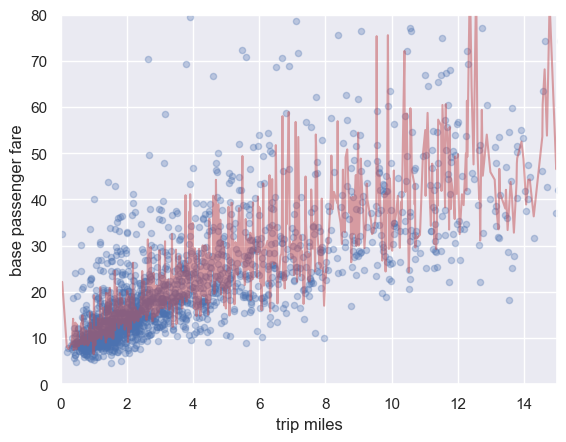

In [6]:
rf_model = RandomForestRegressor()
rf_model.fit(uber_df_2025[['trip_miles']], uber_df_2025[['base_passenger_fare']])

uber_df_with_predictions = (
                                uber_df_2025
                                .assign(model_prediction = lambda df: rf_model.predict(df[['trip_miles']]))
                                .sort_values("trip_miles")
)

print(f"r2 score: {r2_score(uber_df_with_predictions['base_passenger_fare'], uber_df_with_predictions['model_prediction'])}")


fig, ax = plt.subplots()

ax.scatter(
    uber_df_2025['trip_miles'], 
    uber_df_2025['base_passenger_fare'], 
    alpha=0.3,          
    s=20             
    )

ax.plot(
    uber_df_with_predictions['trip_miles'],
    uber_df_with_predictions['model_prediction'],
    'r',
    alpha = 0.5
    )

ax.set_xlim(0, 15)
ax.set_ylim(0,80)

ax.set_xlabel('trip miles', fontsize=12)
ax.set_ylabel('base passenger fare', fontsize=12)

plt.show()


Oefening 1.4: Naar productie! Lees ../data/uber_X_2026.csv in en maak voorspellingen van de passenger_fare op basis van jou in 1.2 en 1.3 getrainede lineaire regressie en random forest model. Welk model zou jij je stakeholders aanraden om te gebruiken? 

In [7]:
uber_X_2026 = pd.read_csv('../../data/uber_X_2026.csv') # Adjust path to file location
uber_X_2026

,ride_id,request_datetime,pickup_zone_id,dropoff_zone_id,trip_miles
0,19417210,2026-01-30 09:18:03,241,161,10.96
1,5204124,2026-01-09 15:05:39,185,18,3.01
2,3674288,2026-01-07 00:30:00,234,229,2.86
3,16315866,2026-01-25 01:16:38,37,17,2.08
4,7362081,2026-01-12 13:38:06,7,196,5.72
...,...,...,...,...,...
9995,494836,2026-01-01 15:19:59,79,170,1.98
9996,20679598,2026-01-31 18:41:50,230,158,2.90
9997,17870438,2026-01-28 09:40:46,233,234,2.61
9998,17745208,2026-01-28 05:27:19,216,132,2.72


In [8]:
uber_X_2026_with_predictions = uber_X_2026.assign(
    lr_prediction = lambda df: lr_model.predict(df[['trip_miles']]),
    rf_prediction = lambda df: rf_model.predict(df[['trip_miles']]),
)

uber_X_2026_with_predictions.sample(10)

,ride_id,request_datetime,pickup_zone_id,dropoff_zone_id,trip_miles,lr_prediction,rf_prediction
3309,9234101,2026-01-15 14:49:43,26,89,1.07,12.873042,10.303967
2197,2734362,2026-01-05 10:36:47,241,265,7.43,32.324372,31.529700
6455,840040,2026-01-02 08:49:09,157,40,8.39,35.260421,38.169200
1137,7283916,2026-01-12 10:33:56,17,217,1.06,12.842458,12.344418
3244,17213566,2026-01-27 09:58:19,257,188,3.26,19.570905,18.859968
3308,19724229,2026-01-30 17:29:39,197,197,1.26,13.454135,14.248232
8060,13582641,2026-01-21 14:59:46,235,153,3.14,19.203899,20.554175
7262,6094919,2026-01-10 17:54:53,209,13,0.79,12.016694,9.298902
8030,7345213,2026-01-12 13:19:50,182,250,1.04,12.781290,8.436154
5481,1438689,2026-01-03 06:29:48,47,235,6.73,30.183502,22.367400


Oefening 1.5: Laten we bekijken hoe goed de modellen het gedaan hebben. Lees ..data/uber_y_2026.csv in en bereken de r2 score van je voorspellingen, voor zowel de lineaire regressie als de random forest, met r2_score(df['base_passenger_fare'], df['jouw_voorspelling']). Hoe kan dit? Hoe had je dit van te voren kunnen weten?

In [9]:
uber_Y_2026 =  pd.read_csv('../../data/uber_Y_2026.csv')
uber_Y_2026

,ride_id,base_passenger_fare
0,19417210,41.78
1,5204124,15.78
2,3674288,18.76
3,16315866,17.01
4,7362081,23.66
...,...,...
9995,494836,8.97
9996,20679598,26.68
9997,17870438,33.21
9998,17745208,17.05


In [10]:
uber_df_2026_with_predictions = uber_X_2026_with_predictions.merge(uber_Y_2026, on = 'ride_id')
uber_df_2026_with_predictions

,ride_id,request_datetime,pickup_zone_id,dropoff_zone_id,trip_miles,lr_prediction,rf_prediction,base_passenger_fare
0,19417210,2026-01-30 09:18:03,241,161,10.96,43.120471,50.056400,41.78
1,5204124,2026-01-09 15:05:39,185,18,3.01,18.806309,21.598307,15.78
2,3674288,2026-01-07 00:30:00,234,229,2.86,18.347551,14.752529,18.76
3,16315866,2026-01-25 01:16:38,37,17,2.08,15.962011,15.170498,17.01
4,7362081,2026-01-12 13:38:06,7,196,5.72,27.094533,25.315317,23.66
...,...,...,...,...,...,...,...,...
9995,494836,2026-01-01 15:19:59,79,170,1.98,15.656172,18.706251,8.97
9996,20679598,2026-01-31 18:41:50,230,158,2.90,18.469887,21.393782,26.68
9997,17870438,2026-01-28 09:40:46,233,234,2.61,17.582955,19.937838,33.21
9998,17745208,2026-01-28 05:27:19,216,132,2.72,17.919377,21.939277,17.05


In [11]:
print(f"R2 score linear regression: {r2_score(uber_df_2026_with_predictions['base_passenger_fare'], uber_df_2026_with_predictions['lr_prediction'])}")
print(f"R2 score random forest: {r2_score(uber_df_2026_with_predictions['base_passenger_fare'], uber_df_2026_with_predictions['rf_prediction'])}")

R2 score linear regression: 0.6662885702941643
R2 score random forest: 0.5774068647339263


Oefening 1.6: Splits de dataset uit 2025 met onderstaande code in een 'train' (80% v.d. data) en een 'test' (20% v.d. data) set. Train dezelfde modellen als in 1.2-1.3, maar doe dit enkel op de train set. Doe vervolgende een voorspelling op de test set en bereken op deze test set de r2 score. Is dit denk je een goede inschatting van hoe de modellen in productie presteren? 

In [12]:
from sklearn.model_selection import train_test_split

In [13]:
uber_df_2025 = pd.read_csv('../../data/uber_2025.csv') # Adjust path to file location
train_set, test_set =  train_test_split(uber_df_2025, test_size = 0.2)

In [14]:
lr_model, rf_model = LinearRegression(), RandomForestRegressor()
lr_model.fit(train_set[['trip_miles']], train_set[['base_passenger_fare']])
rf_model.fit(train_set[['trip_miles']], train_set[['base_passenger_fare']])

test_set_with_predictions = test_set.assign(
    lr_prediction = lambda df: lr_model.predict(df[['trip_miles']]),
    rf_prediction = lambda df: rf_model.predict(df[['trip_miles']]),
)

print(f"R2 score linear regression: {r2_score(test_set_with_predictions['base_passenger_fare'], test_set_with_predictions['lr_prediction'])}")
print(f"R2 score random forest: {r2_score(test_set_with_predictions['base_passenger_fare'], test_set_with_predictions['rf_prediction'])}")

c:\Users\testadmin\Documents\repos\data-analytics-course-python\.venv\Lib\site-packages\sklearn\base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


R2 score linear regression: 0.6591373894370687
R2 score random forest: 0.5221065179915337


Bonus: Oefening 1.7: Herhaal 1.2-1.3 met een sklearn.model.QuantileRegressor. Doet deze het beter dan de lineaire regressie? Met welke loss functie moet je dit meten? Verandere het quantile argument en bekijk hoe de plot verandert.

Bonus: Oefening 1.8: Gebruik een bootstrap confidence interval om de foutmarge om de op de testset (in 1.6) berekende r2 score in te schatten. Wat zegt dit?

In [15]:
from scipy.stats import bootstrap

In [16]:
rng = np.random.default_rng(seed = 42)

In [17]:
lr_data = [test_set_with_predictions['base_passenger_fare'].to_numpy(),test_set_with_predictions['lr_prediction'].to_numpy()]
bootstrap(lr_data, lambda base_passenger_fare, lr_prediction: r2_score(base_passenger_fare, lr_prediction), confidence_level=0.95, random_state = rng, paired=True).confidence_interval

ConfidenceInterval(low=np.float64(0.580657703997481), high=np.float64(0.7219319612439189))

In [18]:
rf_data = [test_set_with_predictions['base_passenger_fare'].to_numpy(),test_set_with_predictions['rf_prediction'].to_numpy()]
bootstrap(rf_data, lambda base_passenger_fare, rf_prediction: r2_score(base_passenger_fare, rf_prediction), confidence_level=0.95, random_state = rng, paired=True).confidence_interval

ConfidenceInterval(low=np.float64(0.41660224331922086), high=np.float64(0.607821347190793))

TODO: Seed?

# Exploration

Oefening 2.1: Een Portugese bank wil voorspellen welk klanten zich in zullen schrijven voor een termijndeposito (dwz., een spaarrekening waar het geld voor een bepaalde tijd vast staat). Ze willen in het bijzonder onderzoeken of ze dit aan de hand van recent marketing contact (de bank belt regelmatig klanten) kunnen voorspellen.
Maak (zonder de data te zien) een aantal hypothesen (bonuspunten voor een hypotheseboom): Wat bepaalt of klanten zich in zullen schrijven? Welke data zouden we willen hebben om dit te voorspellen?

Oefening 2.2 Bekijk de ../data/bank_data.csv en ../data/bank_data_description.md bestanden. Bekijk ook je antwoord op oefening 2.1. Wat kun je uit deze data halen waarmee je denkt deze voorspellingen te kunnen doen?

Oefening 2.3 Exploreer deze data. Heroverweeg je antwoord op 2.2. Waar moeten we in ieder geval rekening mee houden?

In [19]:
bank_df = pd.read_csv("../../data/bank_data.csv") # Adjust path to present location
bank_df.sample(10)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
12434,45,admin.,divorced,university.degree,no,no,no,cellular,jul,mon,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.960,5228.1,no
3392,41,blue-collar,married,basic.4y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.860,5191.0,no
1759,24,services,single,high.school,no,no,yes,telephone,may,fri,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
26005,35,entrepreneur,divorced,university.degree,no,no,no,cellular,nov,wed,...,4,999,0,nonexistent,-0.1,93.200,-42.0,4.120,5195.8,no
5095,53,blue-collar,married,basic.9y,no,no,yes,telephone,may,fri,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
31780,37,blue-collar,married,basic.4y,no,yes,no,cellular,may,thu,...,1,999,1,failure,-1.8,92.893,-46.2,1.327,5099.1,no
16533,31,services,divorced,high.school,no,no,no,telephone,jul,wed,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.963,5228.1,no
36554,30,admin.,single,university.degree,no,no,no,cellular,jun,wed,...,1,999,0,nonexistent,-2.9,92.963,-40.8,1.260,5076.2,no
10796,38,blue-collar,divorced,basic.6y,no,yes,no,telephone,jun,wed,...,6,999,0,nonexistent,1.4,94.465,-41.8,4.962,5228.1,no
27639,52,services,divorced,basic.4y,unknown,yes,yes,cellular,nov,fri,...,8,999,0,nonexistent,-0.1,93.200,-42.0,4.021,5195.8,no


In [20]:
bank_df.shape

(41188, 21)

In [21]:
bank_df.dtypes

age                 int64
job                   str
marital               str
education             str
default               str
housing               str
loan                  str
contact               str
month                 str
day_of_week           str
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome              str
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                     str
dtype: object

In [22]:
# Small cleaning
bank_df = bank_df.assign(y = pd.col('y') == 'yes').reset_index(names = 'row_id')
bank_df

,row_id,age,job,marital,education,default,housing,loan,contact,month,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,0,56,housemaid,married,basic.4y,no,no,no,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,False
1,1,57,services,married,high.school,unknown,no,no,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,False
2,2,37,services,married,high.school,no,yes,no,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,False
3,3,40,admin.,married,basic.6y,no,no,no,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,False
4,4,56,services,married,high.school,no,no,yes,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,41183,73,retired,married,professional.course,no,yes,no,cellular,nov,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,True
41184,41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,False
41185,41185,56,retired,married,university.degree,no,yes,no,cellular,nov,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,False
41186,41186,44,technician,married,professional.course,no,no,no,cellular,nov,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,True


In [23]:
# Numerical features, note that:
# - age 17 - 98 (quite extreme).
# - duration is very skewed (but dropped anyway).
# - campaign is also very skewed.
# - pdays - lots of 999 values (missings).
# - previous - mostly zeroes.
#  Target variable distribution: Quite skewed only ~1 in 10 takes the term deposit.
bank_df.describe()

,row_id,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,20593.50000,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,11890.09578,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,0.00000,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,10296.75000,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,20593.50000,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,30890.25000,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,41187.00000,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [24]:
bank_df.corr(numeric_only = True)

,row_id,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
row_id,1.000000,0.003910,0.008529,-0.093589,-0.283919,0.427815,-0.834661,-0.737559,-0.257615,-0.850484,-0.758164,0.292728
age,0.003910,1.000000,-0.000866,0.004594,-0.034369,0.024365,-0.000371,0.000857,0.129372,0.010767,-0.017725,0.030399
duration,0.008529,-0.000866,1.000000,-0.071699,-0.047577,0.020640,-0.027968,0.005312,-0.008173,-0.032897,-0.044703,0.405274
campaign,-0.093589,0.004594,-0.071699,1.000000,0.052584,-0.079141,0.150754,0.127836,-0.013733,0.135133,0.144095,-0.066357
pdays,-0.283919,-0.034369,-0.047577,0.052584,1.000000,-0.587514,0.271004,0.078889,-0.091342,0.296899,0.372605,-0.324914
previous,0.427815,0.024365,0.020640,-0.079141,-0.587514,1.000000,-0.420489,-0.203130,-0.050936,-0.454494,-0.501333,0.230181
emp.var.rate,-0.834661,-0.000371,-0.027968,0.150754,0.271004,-0.420489,1.000000,0.775334,0.196041,0.972245,0.906970,-0.298334
cons.price.idx,-0.737559,0.000857,0.005312,0.127836,0.078889,-0.203130,0.775334,1.000000,0.058986,0.688230,0.522034,-0.136211
cons.conf.idx,-0.257615,0.129372,-0.008173,-0.013733,-0.091342,-0.050936,0.196041,0.058986,1.000000,0.277686,0.100513,0.054878
euribor3m,-0.850484,0.010767,-0.032897,0.135133,0.296899,-0.454494,0.972245,0.688230,0.277686,1.000000,0.945154,-0.307771


In [25]:
bank_df.isnull().sum()

row_id            0
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [26]:
# pdays variable contains mostly nonsense value '999', so will not be useful for prediction.
bank_df['pdays'].value_counts()

pdays
999    39673
3        439
6        412
4        118
9         64
2         61
7         60
12        58
10        52
5         46
13        36
11        28
1         26
15        24
14        20
8         18
0         15
16        11
17         8
18         7
22         3
19         3
21         2
25         1
26         1
27         1
20         1
Name: count, dtype: int64

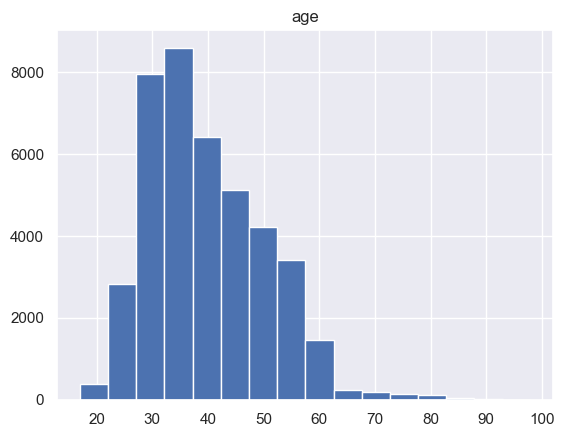

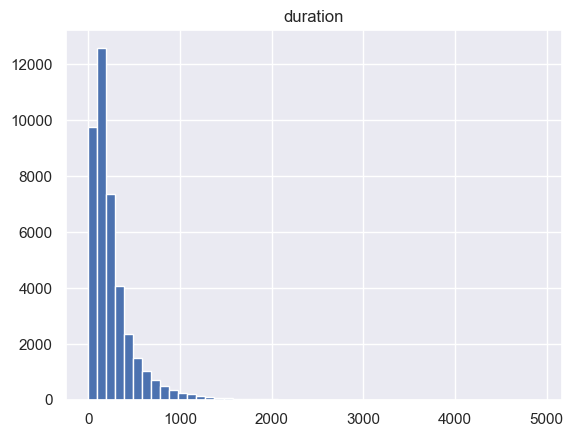

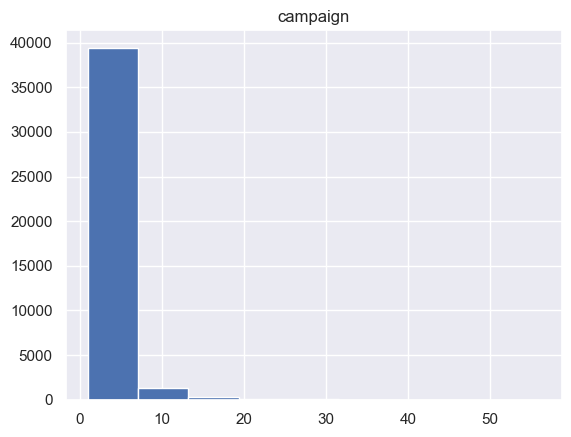

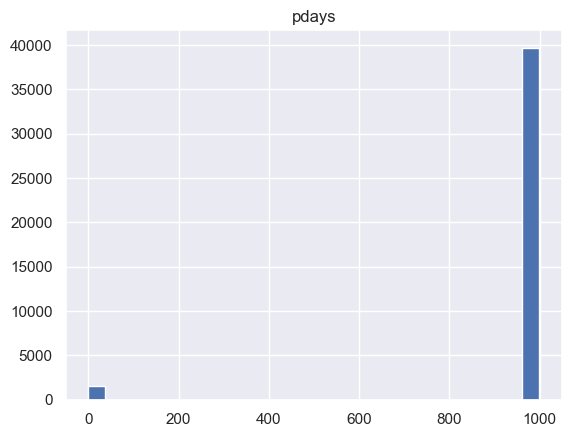

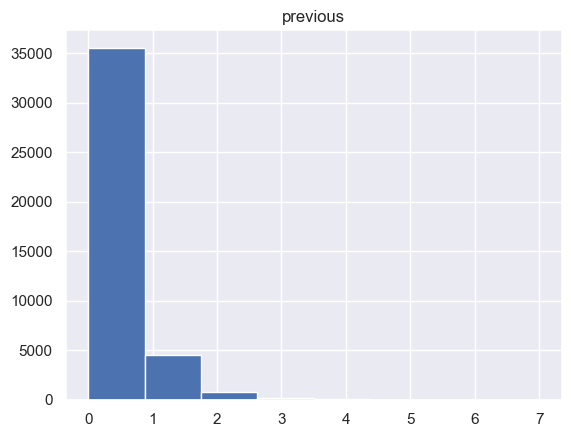

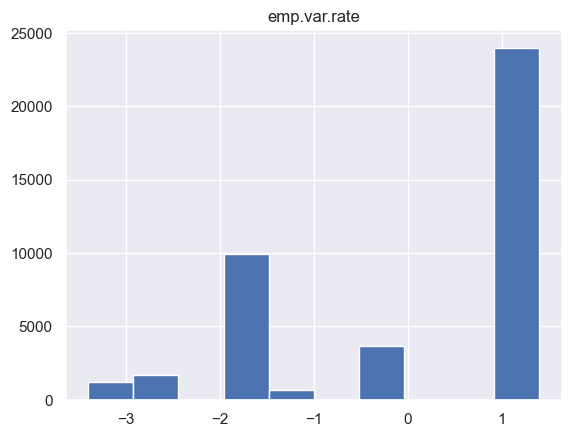

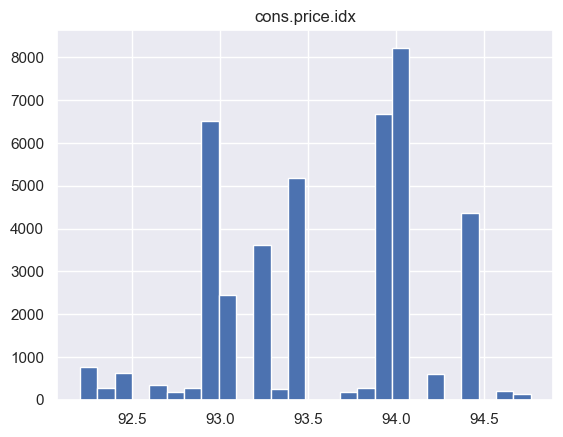

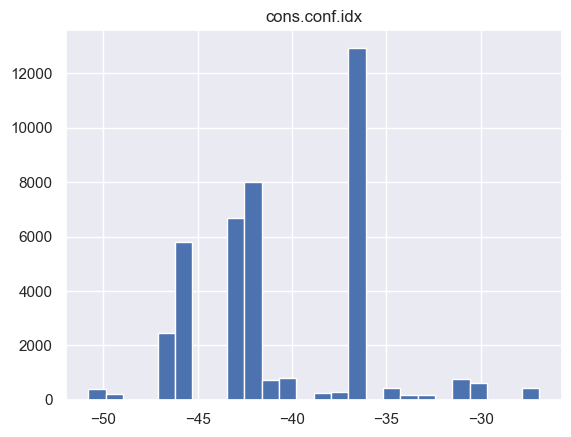

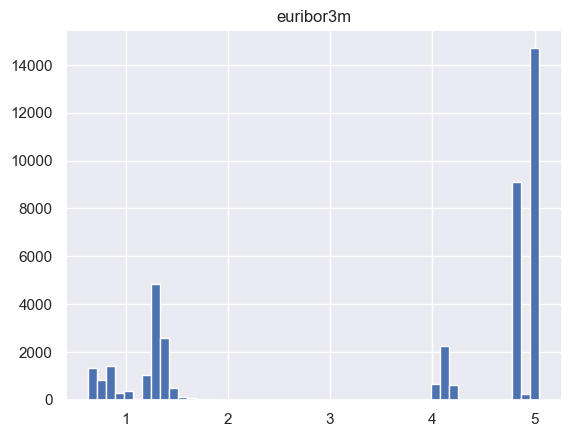

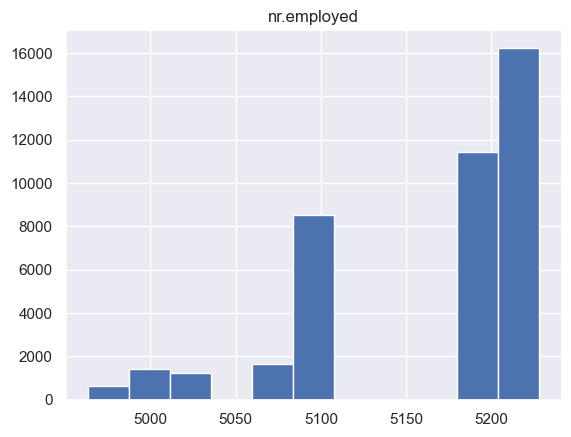

In [27]:
# Plot numeric distributions.
# Note: Macro-economic variables have lots of repeated values.

for col_name in bank_df.drop(columns = 'row_id').select_dtypes("number").columns:
    # Guestimate number of bins.
    bins = bank_df[col_name].nunique()
    bins = bins if bins < 30 else math.ceil(bins / 5)
    bins = bins if bins < 50 else 50

    fig, ax = plt.subplots()
    # Draw the histogram.
    ax.hist(bank_df[col_name], bins=bins, edgecolor="white")
    ax.set_title(col_name)

    plt.show()

In [34]:
# Correlation between numerical features and target variable
(
    bank_df.select_dtypes("number")
    .drop(columns = ['row_id'])
    .corrwith(bank_df["y"])
    .rename("Correlation with target")
    .sort_values(ascending=False)
    .round(2)
    .to_frame()
)

,Correlation with target
duration,0.41
previous,0.23
cons.conf.idx,0.05
age,0.03
campaign,-0.07
cons.price.idx,-0.14
emp.var.rate,-0.30
euribor3m,-0.31
pdays,-0.32
nr.employed,-0.35


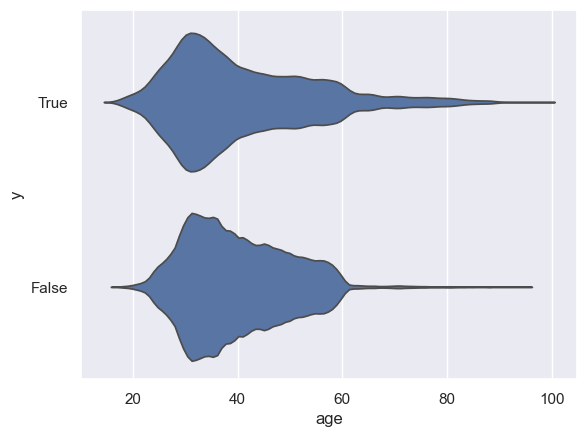

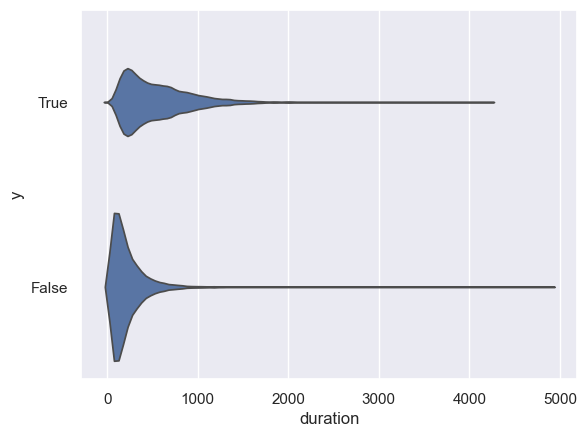

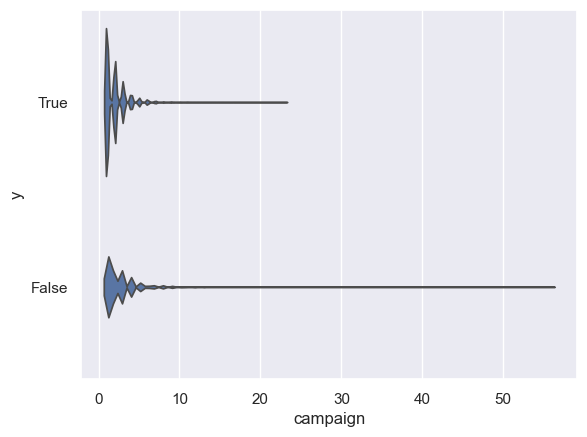

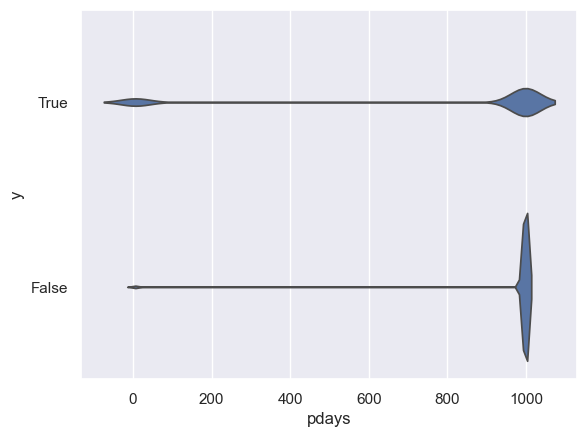

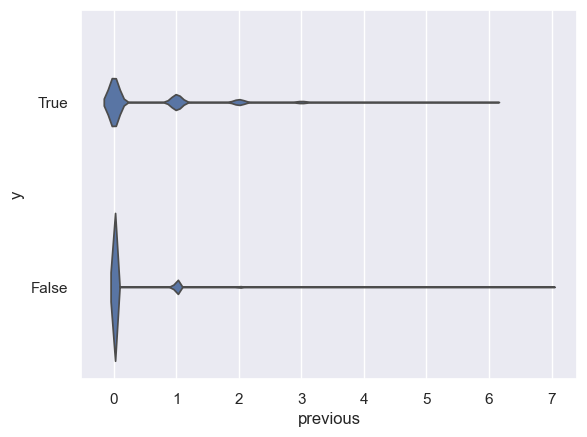

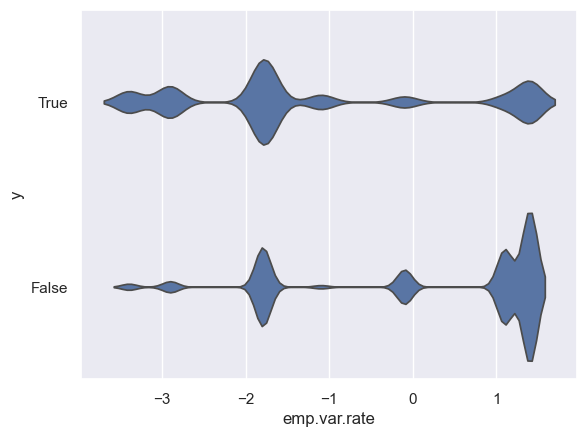

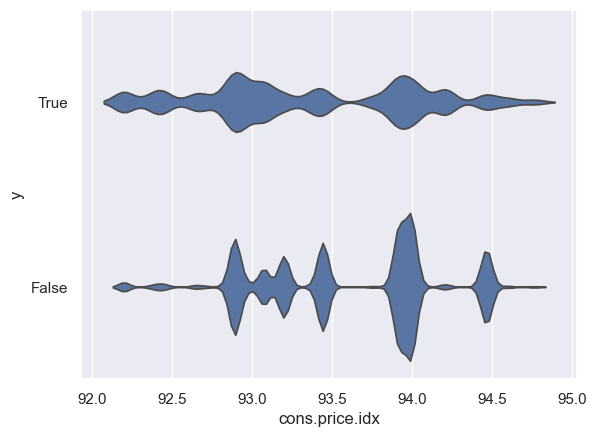

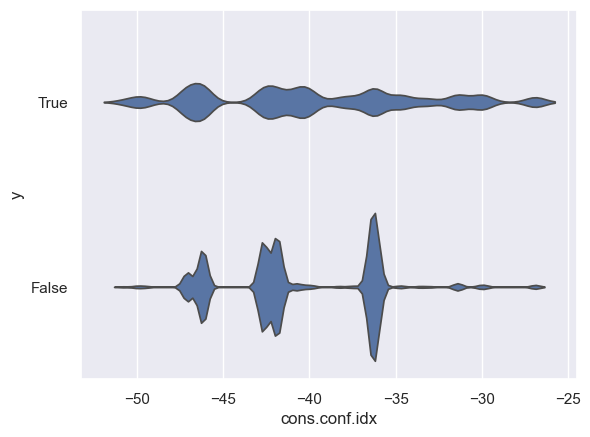

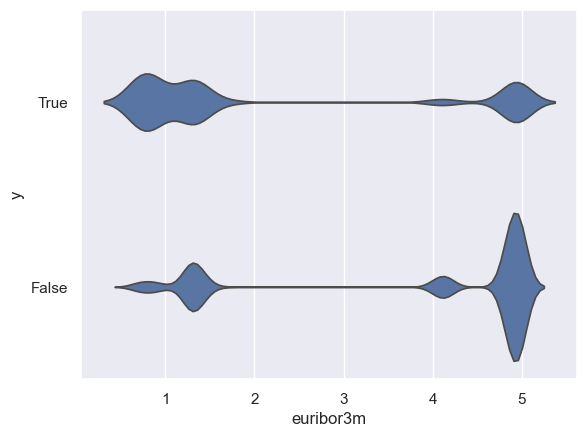

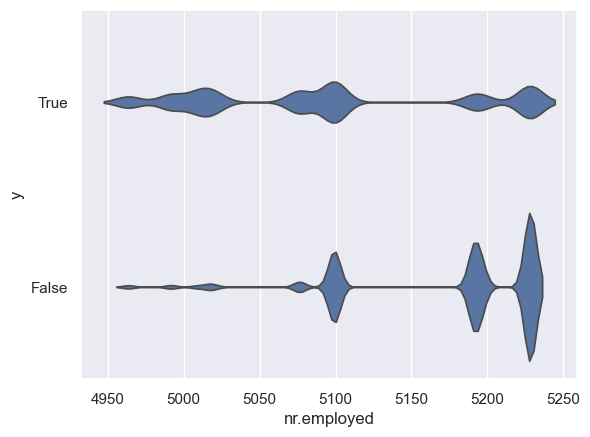

In [33]:
# Plot numeric distributions per value of the target variable.
# Note: Macro-economic variables have lots of repeated values.

for col_name in bank_df.drop(columns = 'row_id').select_dtypes("number").columns:
    fig, ax = plt.subplots()

    sns.violinplot(
        data=bank_df,
        x=col_name,
        y="y",
        inner=None,
        bw_adjust=0.5,
        ax = ax,
        orient="h",
        order = [True, False]
        )

    plt.show()

Relation of macro-economic indicators over time is hard to get from dataset

C:\Users\testadmin\AppData\Local\Temp\2\ipykernel_10352\1272626541.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col_name in bank_df.select_dtypes("object").columns:


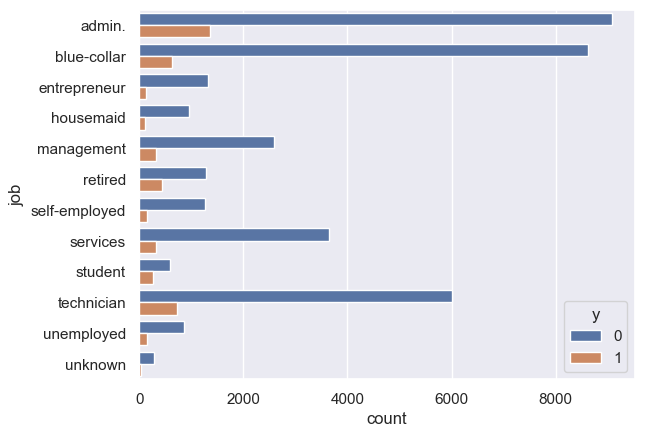

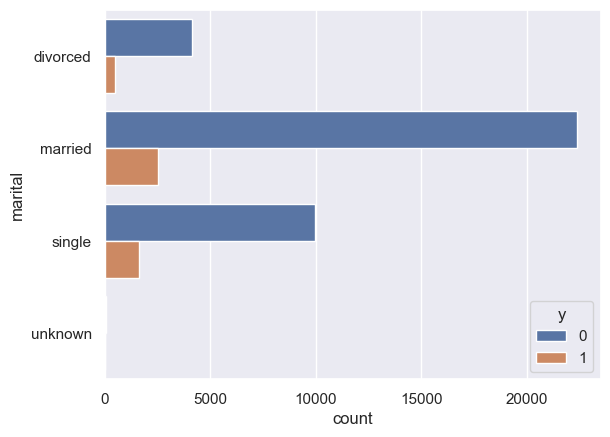

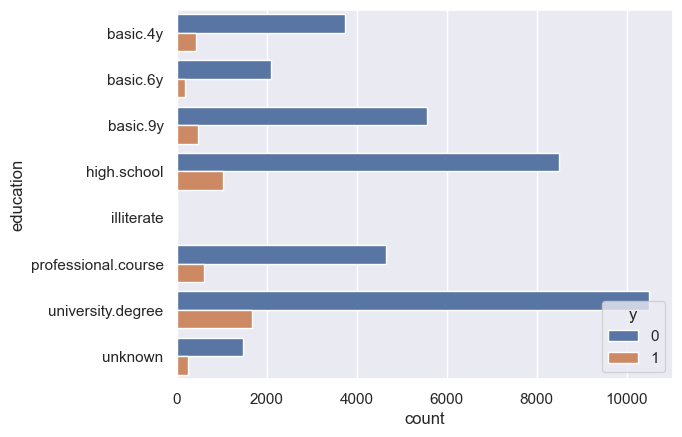

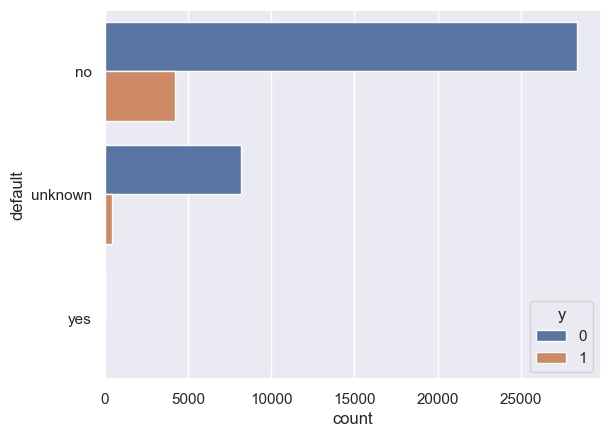

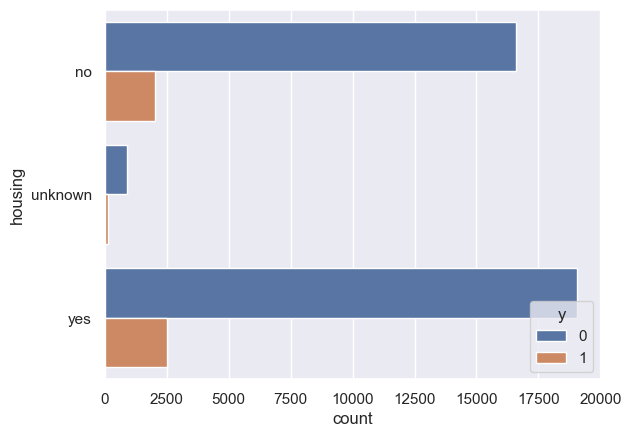

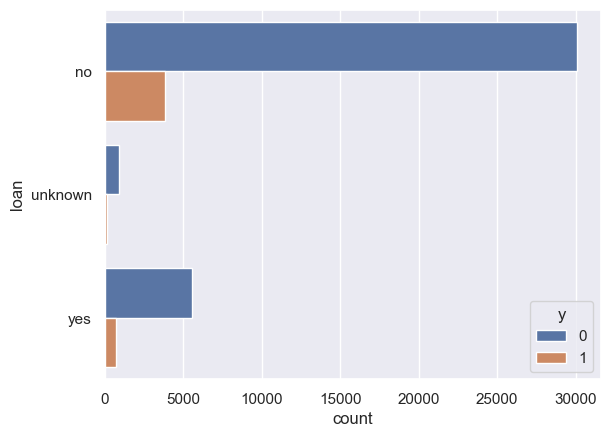

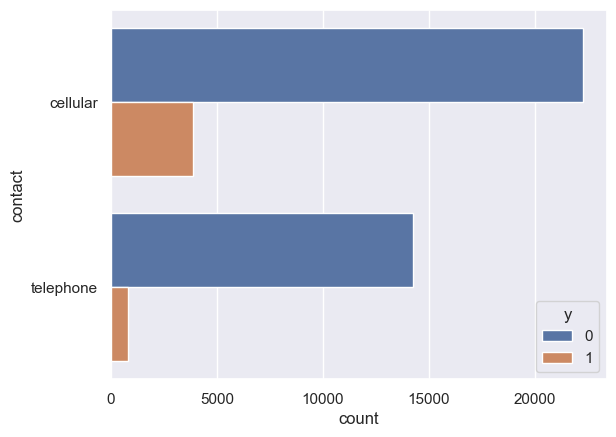

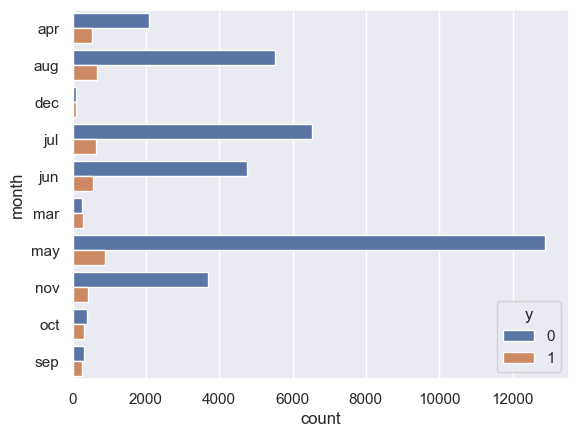

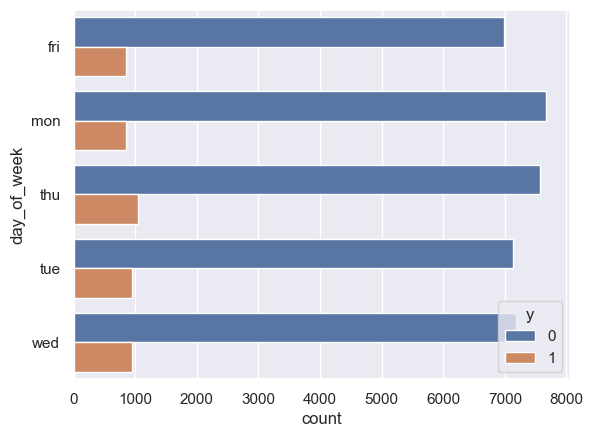

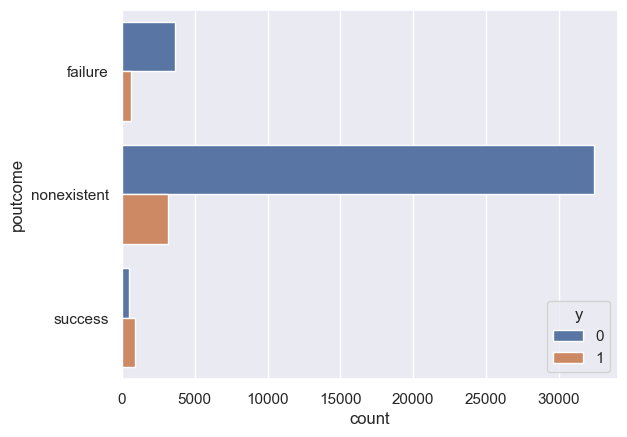

In [134]:
# Plot categorical distributions and relation to y

for col_name in bank_df.select_dtypes("object").columns:


    grouped_df = (    
        bank_df
        .groupby([col_name, 'y'], as_index = False)
        .agg(count = ('row_id', 'count'))
    )

    ax = sns.barplot(data=grouped_df, x="count", y=col_name, hue="y")
    ax.legend(title = "y", loc="lower right")

    plt.show()

# Pre-processing

In [57]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [45]:

bank_train, bank_test = train_test_split(bank_df, test_size = 0.2, random_state = 42)

# sklearn doesn't respect ID as seperate column. Remove and rely on row order
bank_X_train = bank_train.drop(columns = ['row_id', 'duration', 'y'])
bank_y_train = bank_train[['y']]
bank_X_test = bank_test.drop(columns = ['row_id','duration', 'y'])
bank_y_test = bank_test[['y']]

In [ ]:
# Create a OneHotEncoder and StandardScaler.
encoder = OneHotEncoder(sparse_output=False)
scaler = StandardScaler()

In [71]:
transformer = ColumnTransformer(
    transformers=[
        ("encode_categorical", encoder, bank_X_train.select_dtypes('object').columns),
        ("scale_numerical", scaler, bank_X_train.select_dtypes('number').drop(columns = ['pdays']).columns),
    ]
) 

transformer.set_output(transform="pandas")

C:\Users\testadmin\AppData\Local\Temp\2\ipykernel_1852\1690738754.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  ("encode_categorical", encoder, bank_X_train.select_dtypes('object').columns),


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('encode_categorical', ...), ('scale_numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` a

In [54]:
transformer.fit(bank_X_train)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('encode_categorical', ...), ('scale_numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` a

In [55]:
transformer.transform(bank_X_train)

,encode_categorical__job_admin.,encode_categorical__job_blue-collar,encode_categorical__job_entrepreneur,encode_categorical__job_housemaid,encode_categorical__job_management,encode_categorical__job_retired,encode_categorical__job_self-employed,encode_categorical__job_services,encode_categorical__job_student,encode_categorical__job_technician,...,encode_categorical__poutcome_nonexistent,encode_categorical__poutcome_success,scale_numerical__age,scale_numerical__campaign,scale_numerical__previous,scale_numerical__emp.var.rate,scale_numerical__cons.price.idx,scale_numerical__cons.conf.idx,scale_numerical__euribor3m,scale_numerical__nr.employed
12556,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,-0.001669,-0.206242,-0.350902,0.838794,0.589080,-0.472769,0.771354,0.843165
35451,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,-0.864095,0.513676,-0.350902,-1.199440,-1.180760,-1.229916,-1.372028,-0.939748
30592,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.819007,1.233593,1.677559,-1.199440,-1.180760,-1.229916,-1.308581,-0.939748
17914,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.285806,0.873635,-0.350902,0.838794,0.589080,-0.472769,0.771930,0.843165
3315,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,-0.097494,-0.206242,-0.350902,0.647709,0.720307,0.890097,0.713674,0.330405
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6265,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.723182,-0.206242,-0.350902,0.647709,0.720307,0.890097,0.711943,0.330405
11284,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,-0.289144,-0.566200,-0.350902,0.838794,1.533570,-0.278074,0.771930,0.843165
38158,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,-0.480795,-0.566200,1.677559,-2.218556,-1.978483,2.945212,-1.654659,-2.067543
860,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,-0.001669,-0.206242,-0.350902,0.647709,0.720307,0.890097,0.711367,0.330405


In [ ]:
from sklearn.pipeline import Pipeline

In [ ]:
from sklearn.linear_model import LogisticRegressionCV, LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [112]:
model = LogisticRegression()

In [113]:
preprocessor = Pipeline(
    steps=[
        ("transformation", transformer),
    ]
)

pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", model),
    ]
).set_output(transform="pandas")

In [114]:
pipeline.fit(bank_X_train, bank_y_train)

c:\Users\testadmin\Documents\repos\data-analytics-course-python\.venv\Lib\site-packages\sklearn\utils\validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('transformation', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estim

In [115]:
from sklearn.metrics import roc_auc_score

In [116]:
train_predictions =  pipeline.predict(bank_X_train)
test_predictions = pipeline.predict(bank_X_test)

train_performance = roc_auc_score(bank_y_train, train_predictions)
test_performance = roc_auc_score(bank_y_test, test_predictions)

print(f"{train_performance=}, {test_performance=}")

train_performance=0.6084756290162522, test_performance=0.5958827996113237


Oefening 3.x: Bekijk de coefficienten van de regressie. Komen deze overeen met je verwachtingen uit oefening 2.1-2.3?

In [117]:
with pd.option_context(
    'display.max_rows', None,
    'display.max_columns', None,
    'display.width', None,
    'display.max_colwidth', None
):
    print(pd.DataFrame(data = {'feature_names': pipeline.named_steps['preprocessor'].get_feature_names_out(), 'coefficient': pipeline.named_steps['model'].coef_[0]}))

                                        feature_names  coefficient
0                      encode_categorical__job_admin.    -0.000542
1                 encode_categorical__job_blue-collar    -0.107671
2                encode_categorical__job_entrepreneur    -0.077184
3                   encode_categorical__job_housemaid    -0.109873
4                  encode_categorical__job_management    -0.061166
5                     encode_categorical__job_retired     0.213574
6               encode_categorical__job_self-employed    -0.152291
7                    encode_categorical__job_services    -0.119878
8                     encode_categorical__job_student     0.157030
9                  encode_categorical__job_technician     0.062560
10                 encode_categorical__job_unemployed     0.008344
11                    encode_categorical__job_unknown    -0.339374
12               encode_categorical__marital_divorced    -0.220604
13                encode_categorical__marital_married    -0.17

Oefening 3.x: Herhaal oefening 3.x met sklearn.linear_model.LogisticRegression en met sklearn.ensemble.RandomForestRegressor . Hoe doen de train en test scores het?